## <span style="background-color:#FFE6E6"> 언어 모델 & 생성모델 </span>

### <span style="color:violet"> NLP </span>
>NLP(Natural Language Processing): 인간이 쓰는 언어(자연어)를 컴퓨터가 쓰는 언어(프로그래밍 언어)로 처리. -> 숫자(벡터)형태 변환 후, 단어 간 관계와 문맥을 분석

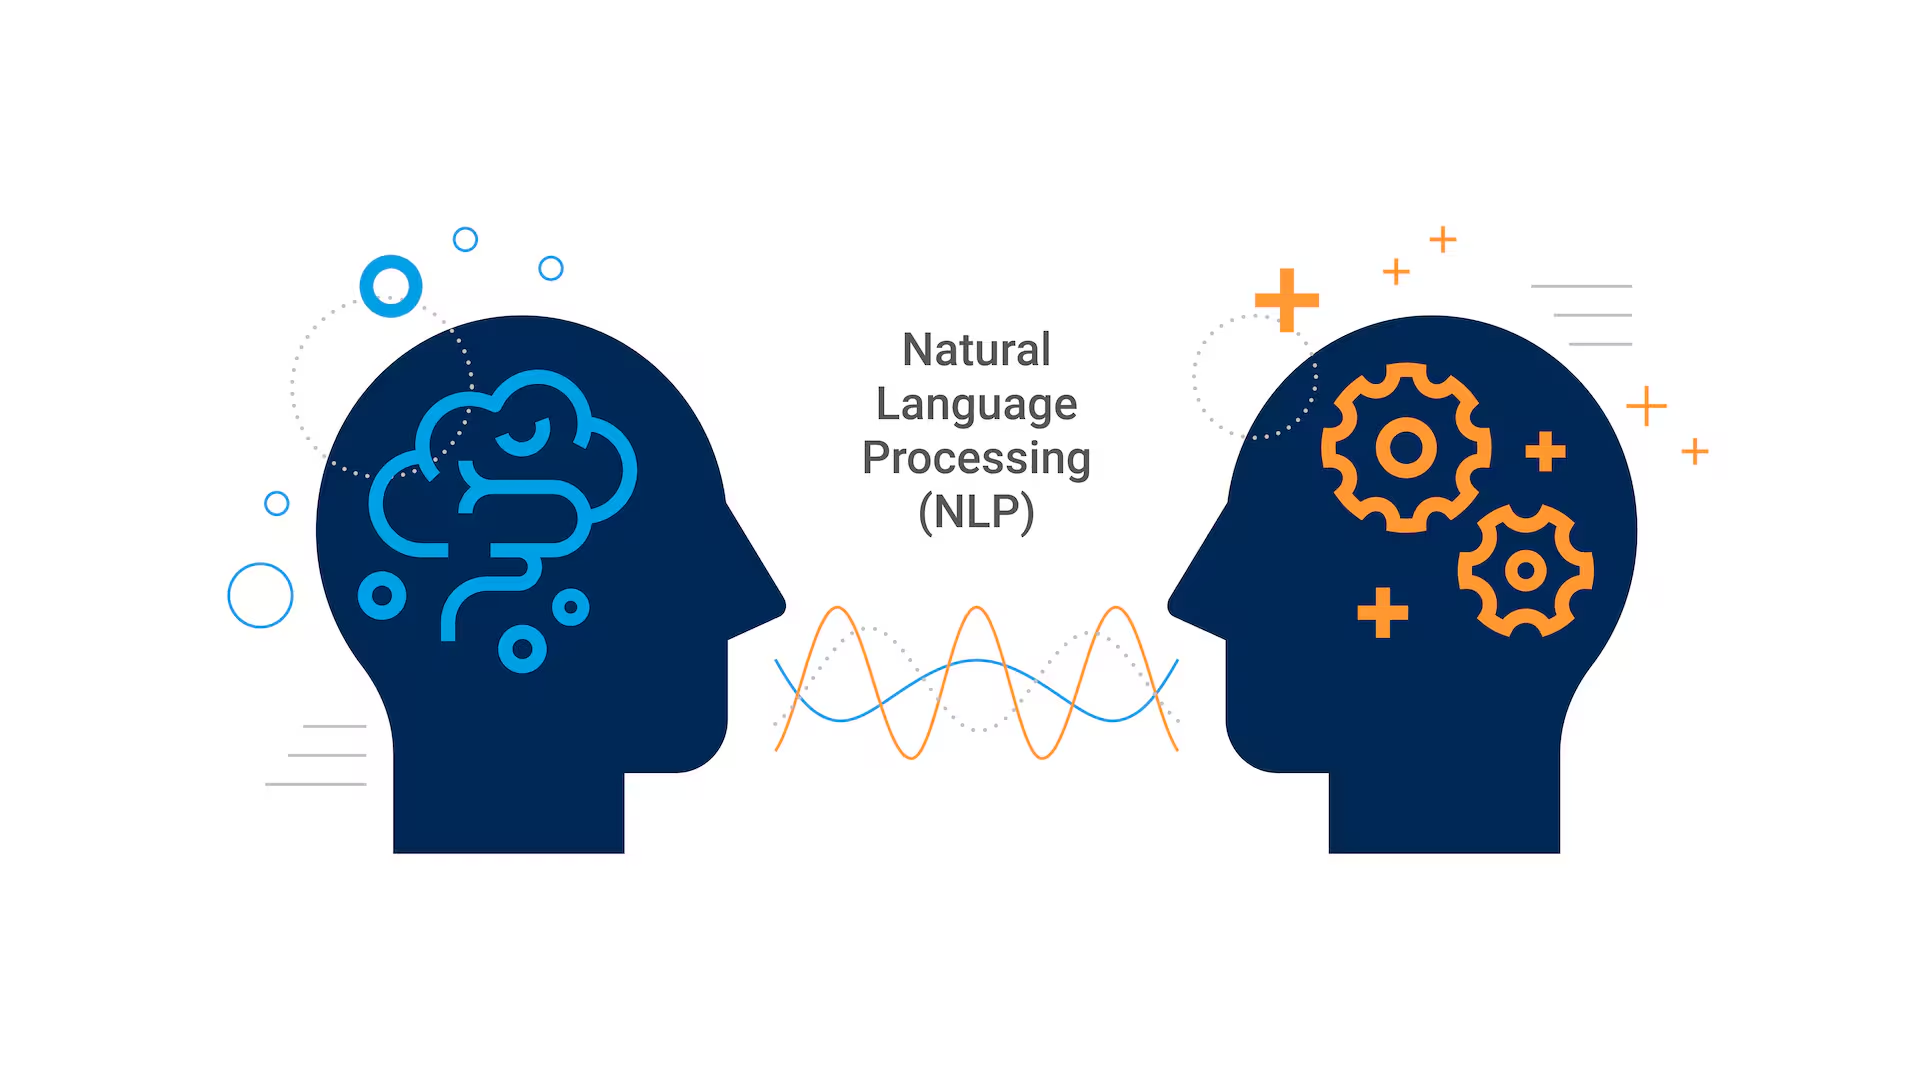

> 자연어의 특징
- 이산적 데이터: 구분된 기호로 구성 -> 컴퓨터가 읽을 수 있도록 숫자 또는 연속적 벡터 변환 필요
- 순차적 데이터: 순서에 따라 읨미가 달라짐 -> 앞뒤 문맥 고려하는 RNN, Transformer 필요
- 중의성과 모호성: 여러가지 의미로 해석 가능 -> 문맥 전체 파악 필요
- 희소성: 단어의 종류와 조합이 매우 다양 -> 학습하지 않은 단어도 유사도를 이용해 확률적으로 추론할 수 있는 능력 필요
- 가변성과 진화: 언어의 지속적 변화 -> 유연하게 패턴을 학습하는 머신러닝 필요.

자연어 처리 분야
- 기계 번역, 감성 분석, 텍스트 분류, 문서 요약, 질의응답 및 챗봇..

### <span style="color:violet"> 통계 기반 언어 모델(SLM) </span>
> 언어 모델: 앞 문맥을 바탕으로 다음 단어의 등장 확률을 예측하는 모델 -> 학습 방식에 따라 SLM(통계 기반) / NLM(신경망 기반)

> SLM과 분포 가설
- 분포 가설: 비슷한 문맥에 나오는 단어는 의미도 비슷하다 (ex. 아침에 **커피/차**를 마셨다) -> 임베딩의 이론적 기반
- 조건부 확률 P(갔다 | 나는 학교에)를 카운트(등장 빈도)로 계산
- 한계: 학습 데이터에 없는 조합은 확률 0 (희소 문제)

> N-gram이 나온 배경과 한계
- 배경: 앞 단어를 전부 고려하면 희소성과 계산량이 커짐 -> 직전 N-1개 단어만 보고 다음 단어 예측
- 한계
    - 희소 문제: N이 커질수록 조합이 급증하고, 데이터에 없는 N-gram은 확률 0
    - 문맥 제한: 멀리 떨어진 단어 사이의 관계를 반영하지 못함

> PPL(Perplexity)
- 모델이 문장을 예측할 때 얼마나 혼란스러워하는지 나타낸 지표 -> **낮을수록 좋음**
- 희소한 문장일수록 높음 / SLM과 NLM 성능 비교에 사용 (ex. SLM 80 vs NLM 25)

> NLM과 SLM의 차이
- SLM: 단어를 개별 기호로 보고 빈도로 계산 -> 의미 관계를 반영하기 어렵고 희소 문제에 취약, 계산 비용은 낮음
- NLM: 단어를 임베딩(연속 벡터)으로 표현하고 신경망으로 학습 -> 의미 유사성 학습, 처음 보는 표현에도 일반화, 계산 비용은 높음

### <span style="color:violet"> 딥러닝기반 모델 </span>
> BERT

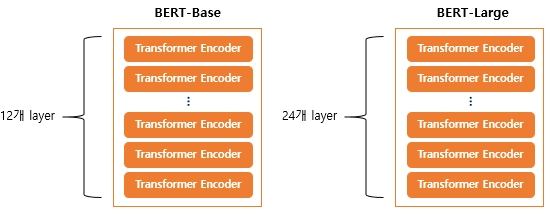

- Transformer **인코더** 기반, 앞뒤 문맥을 모두 보는 **양방향** 모델 -> 언어 **이해**에 특화 (분류, 감성 분석, 개체명 인식)
- 사전학습 -> 파인튜닝
    - MLM: [MASK]로 가린 토큰을 앞뒤 문맥으로 예측
    - NSP: 문장 B가 문장 A의 실제 다음 문장인지 예측

> GPT
- Transformer **디코더** 기반, Masked Self-Attention으로 이전 토큰만 보고 다음 토큰 예측 -> 자기회귀 방식의 **생성**
- GPT-3부터 In-Context Learning: 파인튜닝 없이 프롬프트만으로 작업 수행 (Zero / One / Few-shot)

> LLM

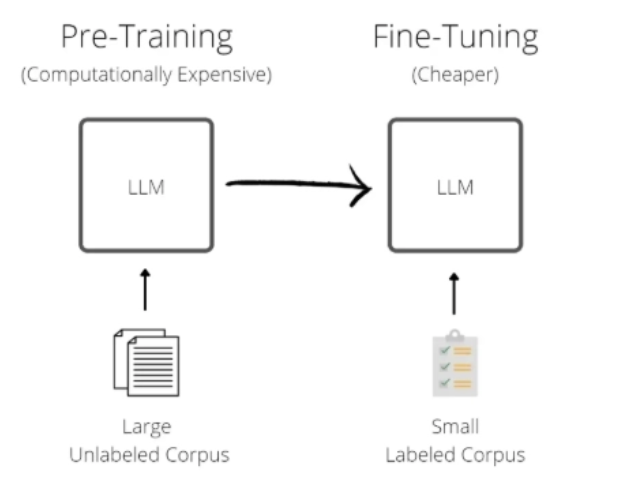
- 방대한 데이터와 대규모 신경망으로 언어를 이해하고 생성하는 모델 -> 생성이 필요하므로 GPT 방식이 널리 쓰임
- 한계: 환각(사실이 아닌 내용을 그럴듯하게 생성), 높은 학습 비용, 최신 정보 반영 불가

> RAG의 구조

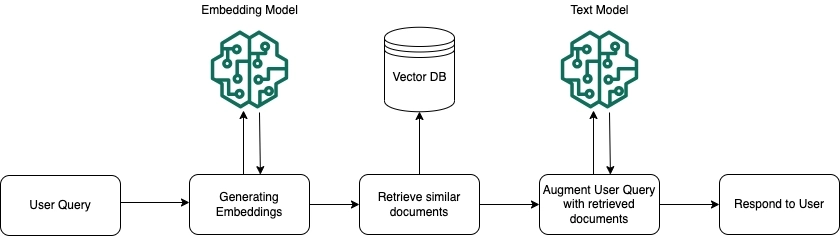
- 외부 지식 검색 + LLM 생성 -> 재학습 없이 정확성과 최신성 향상
- 질의 인코더(질문을 벡터로) -> 지식 검색기(Vector DB에서 유사 문서 검색) -> 지식 증강 생성기(질문 + 문서를 LLM에 넣어 답변)

> LangChain의 아이디어, 특징
- 아이디어: LLM·RAG 구현이 복잡함 -> 기능을 모듈화하고 연결하는 프레임워크
- 특징: 추상화(간단한 인터페이스), 표준화(모델 교체가 쉬움), 체이닝(번역 -> 요약처럼 작업을 연결)

### <span style="color:violet"> sLM </span>
> sLM: LLM보다 작은 언어 모델 -> 자원을 적게 써서 모바일, 온디바이스, 오프라인 추론에 적합

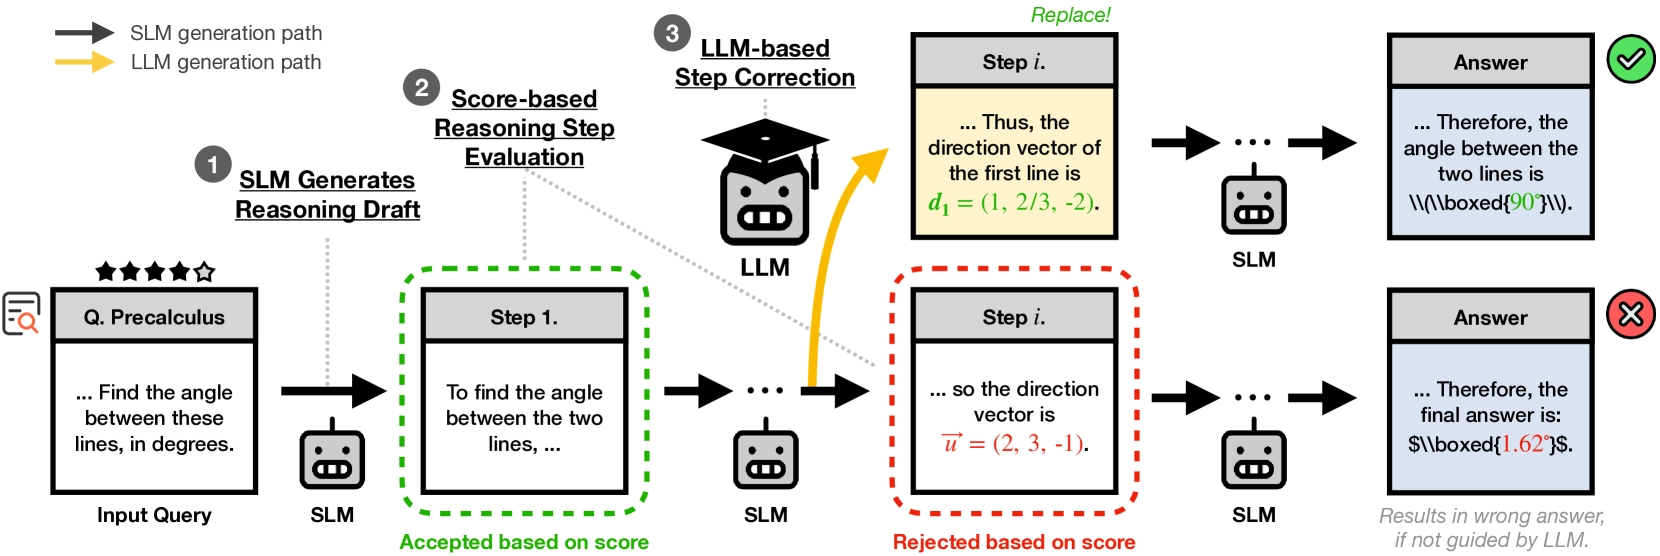

> 모델 압축
- 가지치기(Pruning): 중요도가 낮은 연결이나 뉴런 제거
- 양자화(Quantization): 숫자 정밀도를 낮춤 (FP32 -> INT8)
- 저차원 분해: 큰 행렬을 작은 행렬 두 개의 곱으로 근사 (응용: LoRA)
- 지식 증류: 큰 Teacher 모델의 지식을 작은 Student 모델에 전달 (ex. DistilBERT)

> sLM의 장단점
- 장점: 빠른 응답, 제한된 환경에서도 실행 가능, 데이터 보호, 낮은 비용과 전력
- 단점: 편향, 복잡한 추론에서 성능 저하, 환각

> sLM과 LLM의 결합 (Hybrid Inference)
- 간단한 작업은 sLM, 복잡한 작업은 LLM -> 성능과 비용의 균형

### <span style="color:violet"> 분류모델과 생성모델의 차이 </span>

|분류모델|생성모델|
|---|---|
|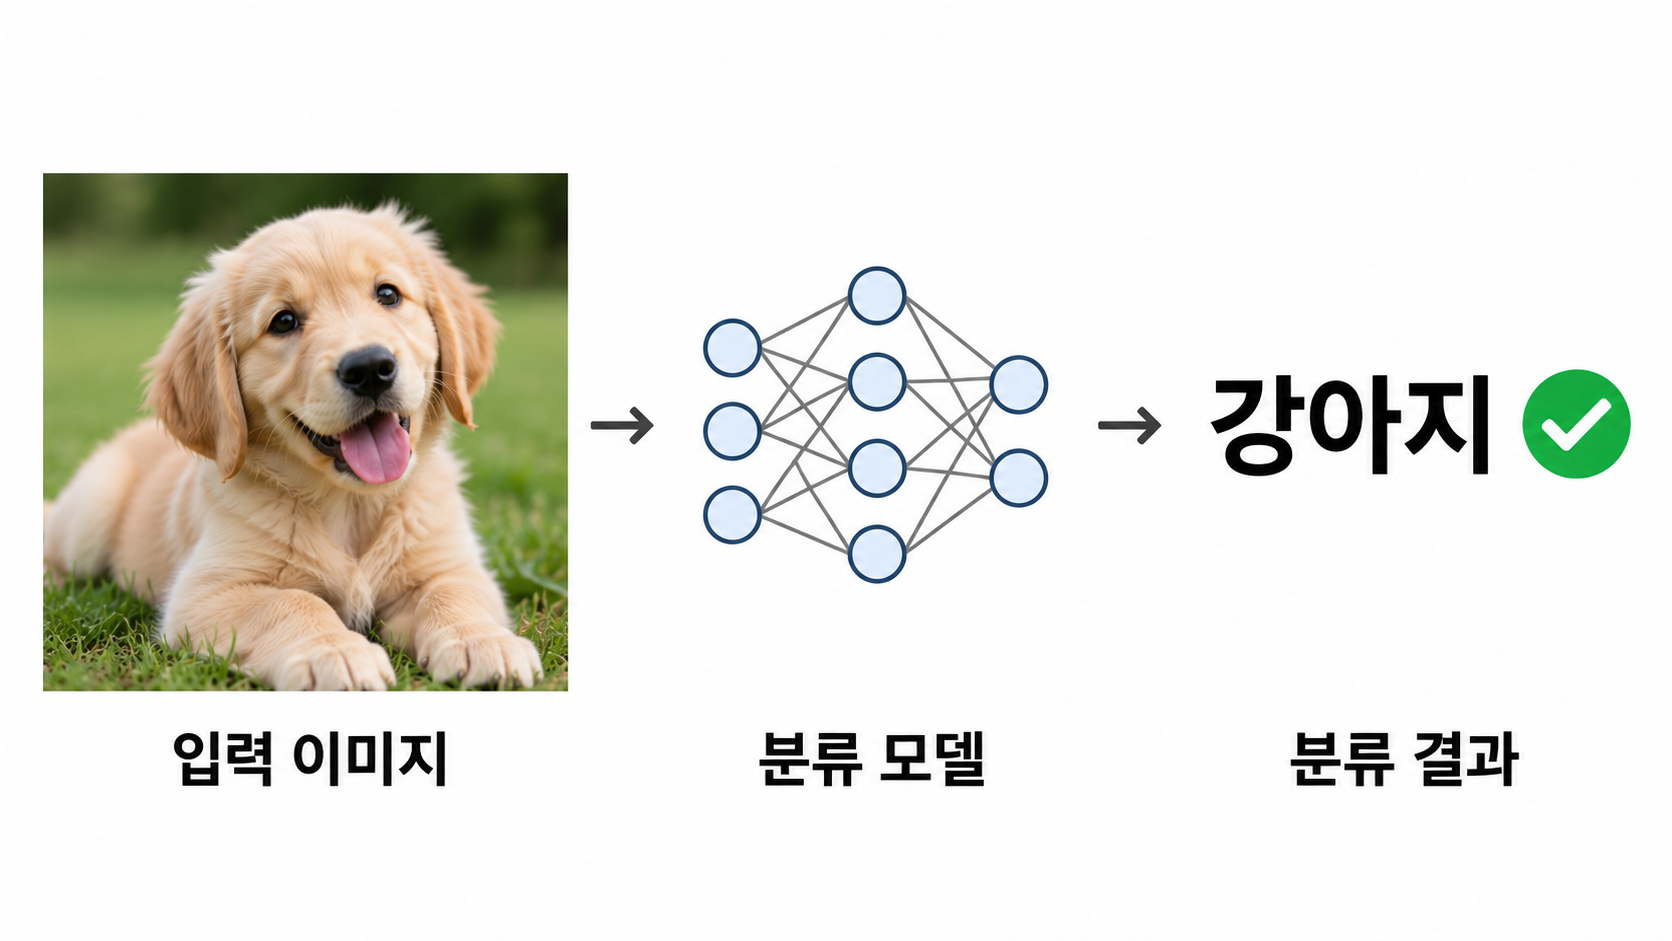|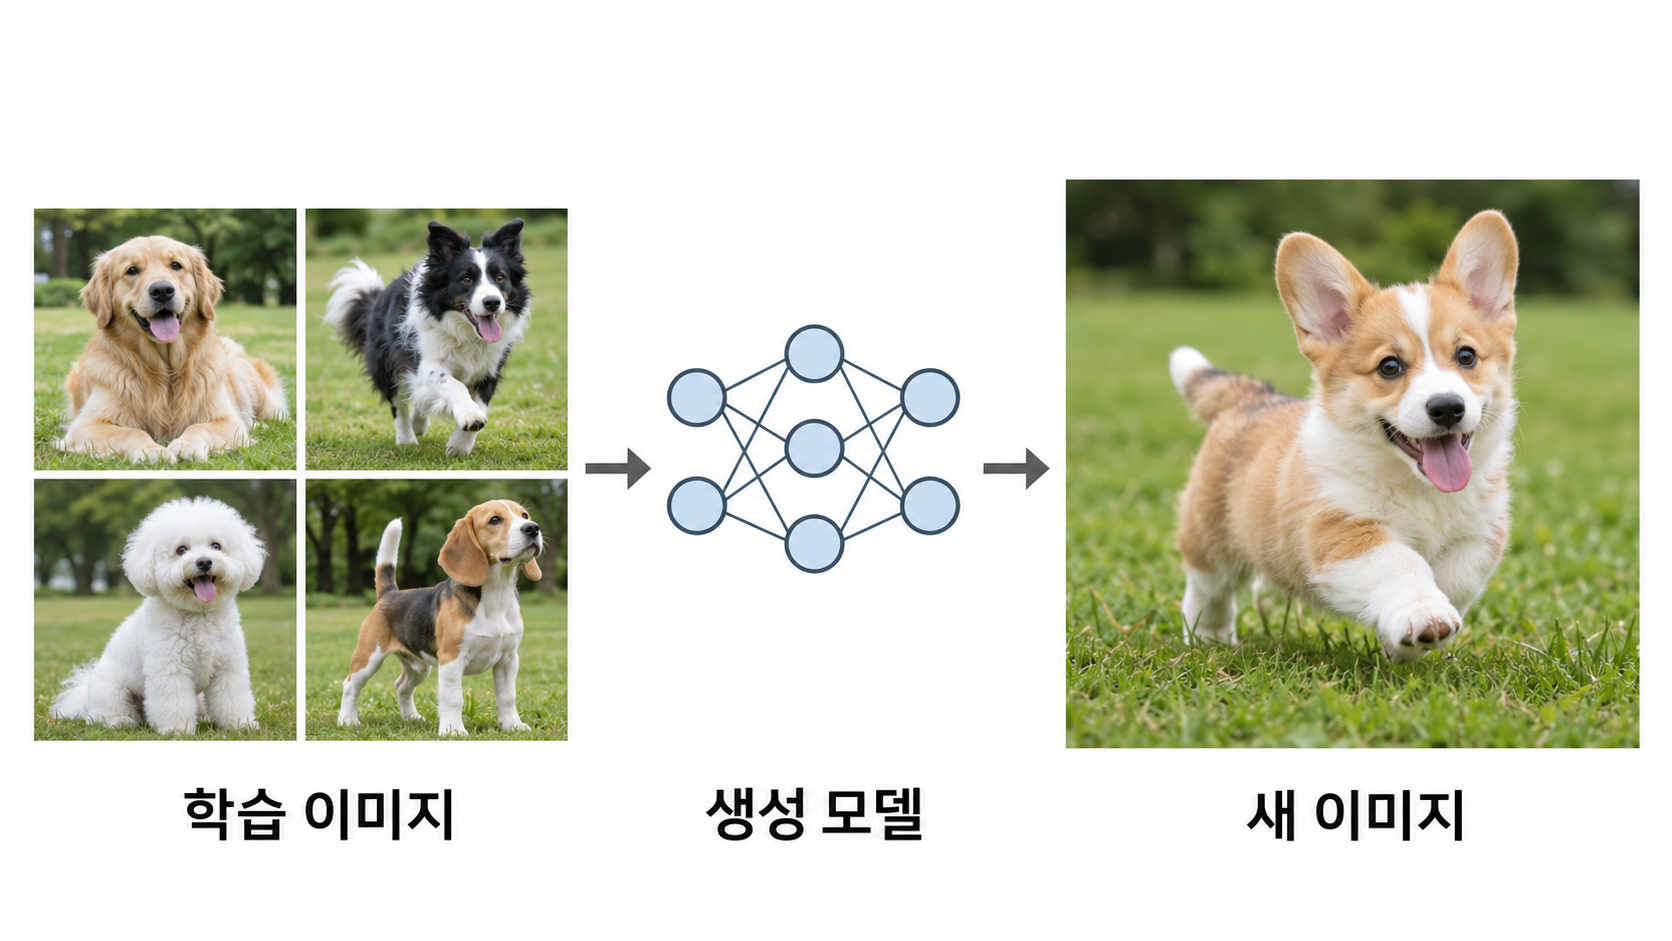|
| P(Y&#124;X)를 학습 -> 데이터 간 차이로 범주 예측 / 처음 보는 데이터도 기존 라벨 중 하나로 분류함 |  P(X)를 학습 -> 데이터의 분포를 따르는 새로운 데이터 생성 / 이상 탐지에도 활용 가능, 품질 평가는 어려움|

### <span style="color:violet"> 생성모델의 분류 </span>
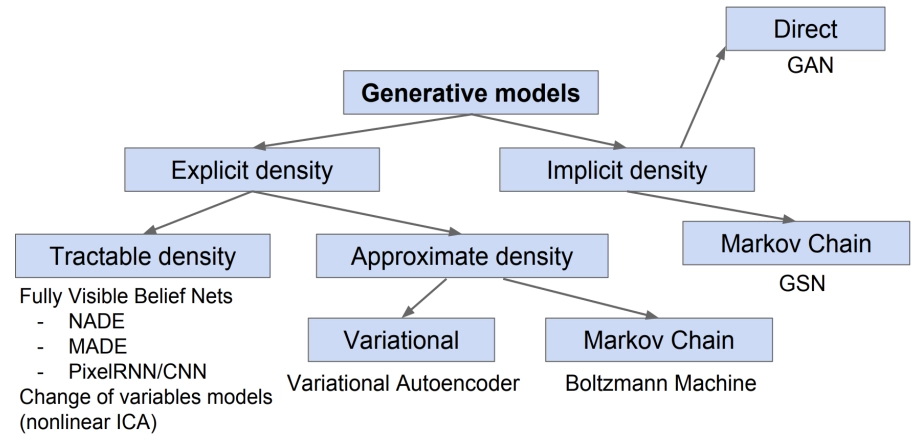
> 기준: 확률밀도 P(X)를 직접 계산할 수 있는가?
- 명시적(Explicit): 계산 가능(PixelRNN 등) / 근사(VAE, Boltzmann Machine)
- 암시적(Implicit): 생성에만 집중 -> 직접 샘플링(GAN) / 반복 샘플링(GSN)

> AE
- 입력을 잠재 벡터 z로 압축(Encoder)했다가 복원(Decoder) -> 복원 오차를 최소화
- 병목에서 공간을 제한해 핵심 특징만 학습하게 함 (압축하지 않으면 그냥 복사해 버림)

> VAE
- AE의 잠재공간은 불규칙해서 새로운 데이터를 생성하기 어려움 -> 입력을 **확률분포(μ, σ)**로 표현
- 학습 목표: 복원 오차 + KL 발산(잠재분포를 표준정규분포에 가깝게) 최소화
- 재파라미터화: 무작위성을 분리해 학습(기울기 전달)이 가능하게 함 -> 분포에서 샘플링해 새로운 데이터 생성

> GAN의 구조와 장단점
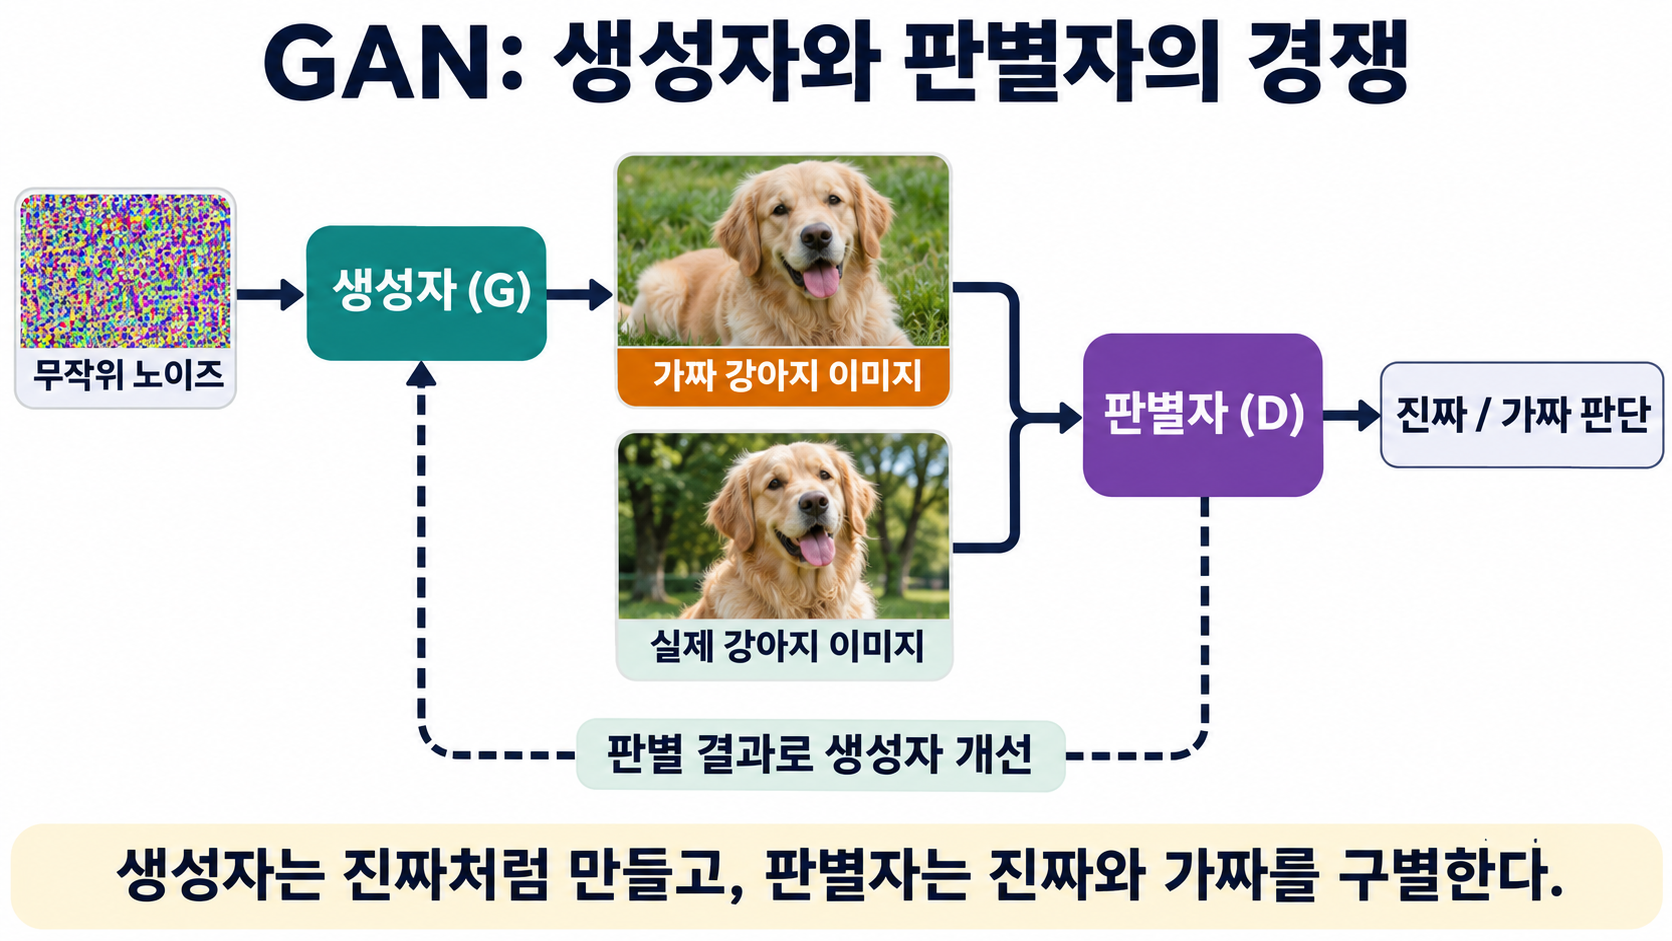
- 구조: 노이즈 z -> 생성자 G(가짜 생성) / 판별자 D(진짜일 확률 0–1 출력) -> 최소-최대 게임 (D는 구별 능력 최대화, G는 D를 속이도록 학습)
- 장점: 사실적이고 선명한 이미지(VAE보다), 한 번 통과로 빠른 생성, 부드러운 잠재공간
- 단점: 학습 불안정, 훈련 초기에 기울기가 약함, 모드 붕괴(비슷한 결과만 생성), 평가 지표의 한계, 역매핑의 어려움

> 확산모델
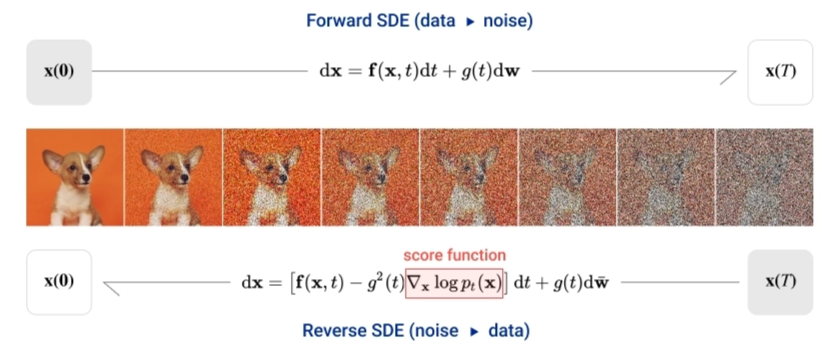
- 노이즈를 추가한 데이터로 학습해 **무작위 노이즈를 점차 제거하면서 새로운 이미지를 생성**하는 모델
- 모호성 모델링: 같은 조건에서도 가능한 결과의 분포를 학습 -> 다양한 이미지 생성
- 순확산: 원본에 가우시안 노이즈를 단계적으로 추가해서 무작위 노이즈로 만듦 -> 역확산 학습용 데이터
- 역확산: x_T에서 Denoising U-Net이 노이즈를 예측하고 조금씩 제거하는 과정을 반복 -> 새로운 이미지
- 장점: GAN보다 높은 품질, 안정적인 학습(MSE로 노이즈 예측), 다양성
- 단점: 반복 단계 때문에 느린 생성, 높은 계산 비용, 단계 구조에 의존 (단계 수에 따라 속도와 품질이 달라짐)


